# Imported lean beef: clean the data, compare a baseline with AutoML

**Question.** Over the last 12 months, could an AutoML model forecast the imported lean beef price 3 months ahead better than simple baselines?

**Data (all from FRED, downloaded as CSV):**

| File | What it is | Unit |
|---|---|---|
| `PBEEFUSDM.csv` | IMF beef price: Australian and New Zealand frozen boneless lean beef, delivered to US ports | US cents per pound |
| `EXUSAL.csv` | Australian dollar exchange rate, monthly average | US dollars per 1 Australian dollar |
| `APU0000703112.csv` | US retail price of 100% ground beef | US dollars per pound |

**How to run.** Upload the three CSV files into the Files panel on the left (the folder icon). Then run the cells from top to bottom with Shift+Enter. Read the printed output after each cell before you move on.

## Step 0. Install AutoGluon

This takes about 3 to 5 minutes. If Colab asks you to restart the session afterwards, click **Restart session**, then continue from Step 1. You do not need to run this cell again.

In [1]:
!pip install -q autogluon.timeseries

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.29.1+cu130 requires torch>=2.14.0, but you have torch 2.13.0 which is incompatible.


In [1]:
import torch, autogluon.timeseries
print(torch.__version__, autogluon.timeseries.__version__)

2.13.0+cu130 1.6.3


## Step 1. Settings

Everything you might want to change is in this one cell.

In [2]:
import hashlib, json, os, warnings
from datetime import datetime

import numpy as np
import pandas as pd

DATA_DIR    = "."                   # folder that holds the three FRED files
BEEF_FILE   = "PBEEFUSDM.csv"       # target: IMF beef price, US cents per lb
FX_FILE     = "EXUSAL.csv"          # US dollars per 1 Australian dollar
RETAIL_FILE = "APU0000703112.csv"   # US retail ground beef, US dollars per lb

HORIZON    = 3            # forecast 3 months ahead
HOLDOUT    = 12           # test on the last 12 months
SEED       = 42           # fixed random seed, so a rerun gives the same result
TIME_LIMIT = 600          # seconds AutoML may spend training
DASH_START = "2000-01-01" # first month in the Excel data sheet
LB_PER_KG  = 2.20462
EXCLUDED_MODELS = []      # if a model fails to download, add its name here, e.g. ["Toto2"]

RUN_ID  = datetime.now().strftime("%Y%m%d-%H%M%S")
AG_PATH = f"autogluon_runs/{RUN_ID}"
print("Run ID:", RUN_ID)

Run ID: 20261118-152224


## Step 2. Load the three files

Each file is read **as text first**, so pandas cannot guess anything. Then the dates are parsed with an exact format, and the values are turned into numbers. A blank or a `.` becomes a missing value (NaN), never a zero.

The fingerprint (MD5) is a short code that changes if even one character in the file changes. It goes into the log, so anyone can confirm they are using the same file.

In [3]:
def file_md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


def load_fred(filename):
    """Read one FRED CSV and return it as a monthly Series."""
    path = os.path.join(DATA_DIR, filename)
    raw = pd.read_csv(path, dtype=str)                 # text only, no guessing
    date_col, value_col = raw.columns[0], raw.columns[1]
    dates = pd.to_datetime(raw[date_col], format="%Y-%m-%d", errors="coerce")
    values = pd.to_numeric(raw[value_col], errors="coerce")   # "" or "." -> NaN
    s = pd.Series(values.to_numpy(), index=dates, name=value_col)
    print(f"{filename:20s} {len(raw):4d} rows   {s.index.min():%b %Y} to {s.index.max():%b %Y}"
          f"   blank values: {int(s.isna().sum())}")
    return s, file_md5(path)


beef_raw, beef_md5 = load_fred(BEEF_FILE)
fx_raw, fx_md5 = load_fred(FX_FILE)
retail_raw, retail_md5 = load_fred(RETAIL_FILE)

PBEEFUSDM.csv         197 rows   May 2010 to Sep 2026   blank values: 0
EXUSAL.csv            670 rows   Jan 1971 to Oct 2026   blank values: 0
APU0000703112.csv     514 rows   Jan 1984 to Oct 2026   blank values: 2


## Step 3. Check each series

Seven checks for each file. **Nothing is changed here.** The checks only report, so you can decide what to do.

| Check | What it catches |
|---|---|
| Unparsed dates | A date in the wrong format |
| Duplicate months | The same month twice |
| Not first of month | A date that is not a monthly date, such as 2026-09-15 |
| Missing months | A month with no row at all |
| Blank values | A row with an empty value |
| Outside the plausible range | A unit or typing error, such as dollars entered as cents |
| Moves above 10% in a month | A spike worth checking against the source. Big moves can be real. |

In [4]:
def check_series(s, label, low, high):
    full = pd.date_range(s.index.min(), s.index.max(), freq="MS")
    pct = s.pct_change(fill_method=None) * 100
    big = pct[pct.abs() > 10].round(1)
    result = {
        "series": label,
        "rows": len(s),
        "unparsed dates": int(s.index.isna().sum()),
        "duplicate months": int(s.index.duplicated().sum()),
        "not first of month": int((s.index.day != 1).sum()),
        "missing months": len(full.difference(s.index)),
        "blank values": int(s.isna().sum()),
        "outside range": int(((s < low) | (s > high)).sum()),
        "moves above 10%": len(big),
    }
    if result["blank values"]:
        print(f"{label}: blank values in", [f"{d:%b %Y}" for d in s[s.isna()].index])
    if len(big):
        print(f"{label}: big monthly moves (%)", {f"{d:%b %Y}": v for d, v in big.items()})
    return result


checks = pd.DataFrame([
    check_series(beef_raw,   "Beef, US cents/lb",   50, 1000),
    check_series(fx_raw,     "AUD/USD",             0.3, 1.5),
    check_series(retail_raw, "Retail beef, US$/lb", 0.5, 20),
]).set_index("series")
checks

Beef, US cents/lb: big monthly moves (%) {'Dec 2010': 10.6, 'Jul 2014': 13.3, 'Aug 2014': 13.8, 'Nov 2019': 21.4, 'Jan 2020': -15.2}
AUD/USD: big monthly moves (%) {'Dec 1976': -12.7, 'Oct 2008': -15.9}
Retail beef, US$/lb: blank values in ['Oct 2012', 'Oct 2025']
Retail beef, US$/lb: big monthly moves (%) {'Nov 2003': 12.2, 'Jan 2013': 10.6, 'May 2020': 10.1}


,rows,unparsed dates,duplicate months,not first of month,missing months,blank values,outside range,moves above 10%
series,,,,,,,,
"Beef, US cents/lb",197,0,0,0,0,0,0,5
AUD/USD,670,0,0,0,0,0,0,2
"Retail beef, US$/lb",514,0,0,0,0,2,0,3


**Read the output before moving on.**

- Expect one blank value in the retail series: **October 2025**. The US Bureau of Labor Statistics could not collect prices that month because of the government shutdown, and it cannot collect them later. The gap is real, so we keep it as missing. Filling it would invent a number.
- If the beef series has a blank or missing month, stop and look at the source before going further.
- For each big monthly move, find that month on the FRED chart. If the source shows it too, it is a real move and we keep it.

## Step 4. Build one clean monthly table

All three series go onto one calendar of months. Then two new columns convert the beef price into other units. The original columns are never overwritten.

- US cents per lb ÷ 100 × 2.20462 = **US dollars per kg**
- US dollars per kg ÷ (US dollars per AUD) = **Australian dollars per kg**

In [5]:
assert beef_raw.notna().all(), "The beef series has blanks. Check the source first."

start = max(pd.Timestamp(DASH_START), beef_raw.index.min())
months = pd.date_range(start, beef_raw.index.max(), freq="MS")

clean = pd.DataFrame(index=months)
clean.index.name = "month"
clean["beef_usc_lb"]   = beef_raw.reindex(months)
clean["aud_usd"]       = fx_raw.reindex(months)
clean["retail_usd_lb"] = retail_raw.reindex(months)
clean["beef_usd_kg"]   = (clean["beef_usc_lb"] / 100 * LB_PER_KG).round(3)
clean["beef_aud_kg"]   = (clean["beef_usd_kg"] / clean["aud_usd"]).round(3)

clean["note"] = ""
clean.loc[clean["retail_usd_lb"].isna(), "note"] = "Retail price missing in source"
oct25 = pd.Timestamp("2025-10-01")
if oct25 in clean.index and pd.isna(clean.loc[oct25, "retail_usd_lb"]):
    clean.loc[oct25, "note"] = "BLS did not collect October 2025 prices (US government shutdown)"
no_fx = clean["aud_usd"].isna()
clean.loc[no_fx, "note"] = (clean.loc[no_fx, "note"] + "; exchange rate missing in source").str.lstrip("; ")

print(f"{len(clean)} months, {clean.index.min():%b %Y} to {clean.index.max():%b %Y}")
print("Missing values per column:")
print(clean.isna().sum().to_string())
clean.tail(14)

197 months, May 2010 to Sep 2026
Missing values per column:
beef_usc_lb      0
aud_usd          0
retail_usd_lb    2
beef_usd_kg      0
beef_aud_kg      0
note             0


,beef_usc_lb,aud_usd,retail_usd_lb,beef_usd_kg,beef_aud_kg,note
month,,,,,,
2025-08-01,309.428571,0.6495,6.318,6.822,10.503,
2025-09-01,309.909091,0.6598,6.323,6.832,10.355,
2025-10-01,314.000000,0.6547,NaN,6.923,10.574,BLS did not collect October 2025 prices (US go...
2025-11-01,325.500000,0.6502,6.540,7.176,11.037,
2025-12-01,338.652174,0.6643,6.687,7.466,11.239,
2026-01-01,330.954545,0.6792,6.752,7.296,10.742,
2026-02-01,344.500000,0.7060,6.739,7.595,10.758,
2026-03-01,349.772727,0.7017,6.701,7.711,10.989,
2026-04-01,351.409091,0.7093,6.899,7.747,10.922,


**A check you can do by hand.** Take the last row. Divide `beef_usc_lb` by 100, multiply by 2.20462, and you should get `beef_usd_kg`. Then divide by `aud_usd` and you should get `beef_aud_kg`. Do it once on a calculator. If it matches, the conversion is right.

## Step 5. Split the data by time

- **Training data:** everything before the last 12 months. The models learn from this.
- **Holdout:** the last 12 months. No model sees these months while it is being trained.

We forecast the holdout from **four starting points**, three months apart. From each start, every method forecasts the next 3 months, using only data that existed before that start. So each holdout month is forecast exactly once, between 1 and 3 months ahead.

In [6]:
y = beef_raw.astype(float)                   # the full beef series, for modelling
holdout_months = y.index[-HOLDOUT:]
train = y[y.index < holdout_months[0]]
origins = holdout_months[::HORIZON]          # 4 starting points

print(f"Training data: {train.index.min():%b %Y} to {train.index.max():%b %Y} ({len(train)} months)")
print(f"Holdout:       {holdout_months[0]:%b %Y} to {holdout_months[-1]:%b %Y} ({len(holdout_months)} months)")
print("Forecast starts:", [f"{o:%b %Y}" for o in origins])

Training data: May 2010 to Sep 2025 (185 months)
Holdout:       Oct 2025 to Sep 2026 (12 months)
Forecast starts: ['Oct 2025', 'Jan 2026', 'Apr 2026', 'Jul 2026']


## Step 6. Three simple baselines

| Baseline | The forecast for each of the next 3 months is |
|---|---|
| Naive | The last known price |
| Seasonal naive | The price in the same month one year earlier |
| 3-month average | The average of the last 3 known prices |

They take one line each. Every other model has to beat them.

In [7]:
def baseline_forecasts(y, origins, h):
    rows = []
    for origin in origins:
        history = y[y.index < origin]                          # only what was known then
        for step, month in enumerate(pd.date_range(origin, periods=h, freq="MS"), start=1):
            rows.append({
                "month": month,
                "forecast_start": origin,
                "steps_ahead": step,
                "actual": y[month],
                "naive": history.iloc[-1],
                "seasonal_naive": history[month - pd.DateOffset(years=1)],
                "mean_3m": history.iloc[-3:].mean(),
            })
    return pd.DataFrame(rows)


fc = baseline_forecasts(y, origins, HORIZON)
fc.round(2)

,month,forecast_start,steps_ahead,actual,naive,seasonal_naive,mean_3m
0,2025-10-01,2025-10-01,1,314.00,309.91,272.22,308.09
1,2025-11-01,2025-10-01,2,325.50,309.91,269.52,308.09
2,2025-12-01,2025-10-01,3,338.65,309.91,276.23,308.09
3,2026-01-01,2026-01-01,1,330.95,338.65,281.76,326.05
4,2026-02-01,2026-01-01,2,344.50,338.65,285.88,326.05
5,2026-03-01,2026-01-01,3,349.77,338.65,292.17,326.05
6,2026-04-01,2026-04-01,1,351.41,349.77,294.07,341.74
7,2026-05-01,2026-04-01,2,346.14,349.77,292.73,341.74
8,2026-06-01,2026-04-01,3,341.60,349.77,298.26,341.74
9,2026-07-01,2026-07-01,1,331.67,341.60,304.93,346.38


## Step 7. AutoML with AutoGluon

AutoGluon trains several kinds of model on the training data, scores each one on validation windows **inside** the training data, and combines the best into a weighted ensemble. The `medium_quality` preset trains:

- **Statistical models:** SeasonalNaive, ETS, Theta
- **Tree-based models:** RecursiveTabular and DirectTabular, which use LightGBM on lagged values
- **Pretrained forecasting models:** Chronos-2 and Toto-2, downloaded from Hugging Face

`num_val_windows=4` makes AutoGluon pick its models on four 3-month windows at the end of the training data. That mirrors how we test on the holdout.

This cell takes up to `TIME_LIMIT` seconds.

In [8]:
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor


def to_tsdf(series):
    df = pd.DataFrame({"item_id": "beef", "timestamp": series.index, "target": series.to_numpy()})
    return TimeSeriesDataFrame.from_data_frame(df, id_column="item_id", timestamp_column="timestamp")


predictor = TimeSeriesPredictor(
    prediction_length=HORIZON,
    target="target",
    eval_metric="MAE",
    freq="MS",
    quantile_levels=[0.1, 0.5, 0.9],
    path=AG_PATH,
)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    predictor.fit(
        to_tsdf(train),
        presets="medium_quality",
        time_limit=TIME_LIMIT,
        num_val_windows=4,
        excluded_model_types=EXCLUDED_MODELS,
        random_seed=SEED,
    )
n_warnings = len(caught)

leaderboard = predictor.leaderboard()
print("Best model inside AutoML:", predictor.model_best)
print("Warnings during training:", n_warnings, f"(full log: {AG_PATH}/logs/predictor_log.txt)")
leaderboard

Beginning AutoGluon training... Time limit = 600s
AutoGluon will save models to '/content/autogluon_runs/20261118-152224'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.16
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Oct 22 03:07:54 UTC 2026
CPU Count:          2
Pytorch Version:    2.13.0+cu130
CUDA Version:       13.0
GPU Memory:         GPU 0: 14.56/14.56 GB
Total GPU Memory:   Free: 14.56 GB, Allocated: 0.00 GB, Total: 14.56 GB
GPU Count:          1
Memory Avail:       10.76 GB / 12.67 GB (84.9%)
Disk Space Avail:   108.04 GB / 112.64 GB (95.9%)
Setting presets to: medium_quality

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': MAE,
 'excluded_model_types': [],
 'freq': 'MS',
 'hyperparameters': 'light',
 'known_covariates_names': [],
 'num_val_windows': 4,
 'prediction_length': 3,
 'quantile_levels': [0.1, 0.5, 0.9],
 'random_seed': 42,
 'refit_every_n_windows': 1,
 're

config.json:   0%|          | 0.00/969 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  112MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

	-5.9301       = Validation score (-MAE)
	2.40    s     = Training runtime
	0.04    s     = Validation (prediction) runtime
Fitting 1 ensemble(s), in 1 layers.
Training ensemble model WeightedEnsemble. Training for up to 555.2s.
	Ensemble weights: {'ETS': 0.59, 'Toto2': 0.41}
	-5.8133       = Validation score (-MAE)
	1.00    s     = Training runtime
	0.15    s     = Validation (prediction) runtime
Training complete. Models trained: ['SeasonalNaive', 'RecursiveTabular', 'DirectTabular', 'ETS', 'Theta', 'Chronos2', 'Toto2', 'WeightedEnsemble']
Total runtime: 45.67 s
Best model: WeightedEnsemble
Best model score: -5.8133


Best model inside AutoML: WeightedEnsemble
Warnings during training: 114 (full log: autogluon_runs/20261118-152224/logs/predictor_log.txt)


,model,score_val,pred_time_val,fit_time_marginal,fit_order
0,WeightedEnsemble,-5.813297,0.152004,1.002435,8
1,Toto2,-5.930106,0.039803,2.395480,7
2,ETS,-6.412344,0.110357,2.240789,4
3,Theta,-6.652519,0.006994,0.052750,5
4,Chronos2,-7.213099,0.030473,28.939209,6
5,RecursiveTabular,-14.043817,0.046232,1.987235,2
6,DirectTabular,-22.617232,0.050024,3.004213,3
7,SeasonalNaive,-41.409765,0.004941,0.046957,1


**How to read the leaderboard.** `score_val` is the validation score. AutoGluon shows every metric so that higher is better, so the MAE appears as a negative number: −10 is better than −15. These scores come from the **training** period. The fair test is the holdout in the next step.

## Step 8. AutoML forecasts on the holdout

From each of the four starting points, we give the trained models the data known up to that point and ask for the next 3 months. The models are **not retrained** with holdout data.

In [9]:
ag_rows = []
for origin in origins:
    context = y[y.index < origin]
    pred = predictor.predict(to_tsdf(context)).loc["beef"]
    expected = pd.date_range(origin, periods=HORIZON, freq="MS")
    assert list(pred.index) == list(expected), "AutoML forecast months do not line up"
    for month in expected:
        ag_rows.append({"month": month,
                        "automl": pred.loc[month, "mean"],
                        "automl_p10": pred.loc[month, "0.1"],
                        "automl_p90": pred.loc[month, "0.9"]})

fc = fc.merge(pd.DataFrame(ag_rows), on="month", how="left", validate="one_to_one")
assert len(fc) == HOLDOUT and fc["automl"].notna().all()
fc.round(2)

Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble
Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble
Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble
Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble


,month,forecast_start,steps_ahead,actual,naive,seasonal_naive,mean_3m,automl,automl_p10,automl_p90
0,2025-10-01,2025-10-01,1,314.00,309.91,272.22,308.09,309.52,294.29,323.66
1,2025-11-01,2025-10-01,2,325.50,309.91,269.52,308.09,309.62,286.53,331.85
2,2025-12-01,2025-10-01,3,338.65,309.91,276.23,308.09,309.49,280.40,338.07
3,2026-01-01,2026-01-01,1,330.95,338.65,281.76,326.05,341.37,320.88,360.64
4,2026-02-01,2026-01-01,2,344.50,338.65,285.88,326.05,341.73,312.56,371.19
5,2026-03-01,2026-01-01,3,349.77,338.65,292.17,326.05,341.13,305.84,378.98
6,2026-04-01,2026-04-01,1,351.41,349.77,294.07,341.74,350.52,332.27,367.09
7,2026-05-01,2026-04-01,2,346.14,349.77,292.73,341.74,351.23,325.14,376.61
8,2026-06-01,2026-04-01,3,341.60,349.77,298.26,341.74,351.19,318.91,383.40
9,2026-07-01,2026-07-01,1,331.67,341.60,304.93,346.38,339.14,322.52,355.19


## Step 9. Compare every method on the same 12 months

| Metric | Meaning |
|---|---|
| MAE | Average size of the miss, in US cents per lb. Lower is better. |
| MAPE | Average miss as a percentage of the actual price |
| Bias | Average of (actual − forecast). Positive means the method forecast too low. |
| MASE | MAE divided by the 1-month naive error in the training data. It has no unit. |
| Coverage | AutoML only: how often the actual price fell inside its 10% to 90% range. About 80% is the target. |

In [10]:
scale = train.diff().abs().mean()      # average 1-month change in the training data
methods = {"Naive": "naive", "Seasonal naive": "seasonal_naive",
           "3-month average": "mean_3m", "AutoML (AutoGluon)": "automl"}

rows = []
for name, col in methods.items():
    err = fc["actual"] - fc[col]
    rows.append({"method": name,
                 "MAE": err.abs().mean(),
                 "MAPE_%": (err.abs() / fc["actual"]).mean() * 100,
                 "bias": err.mean(),
                 "MASE": err.abs().mean() / scale})
results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True).round(2)

coverage = ((fc["actual"] >= fc["automl_p10"]) & (fc["actual"] <= fc["automl_p90"])).mean() * 100
best_baseline = results[results["method"] != "AutoML (AutoGluon)"].iloc[0]
automl = results[results["method"] == "AutoML (AutoGluon)"].iloc[0]
change = (automl["MAE"] / best_baseline["MAE"] - 1) * 100

print(f"Best baseline: {best_baseline['method']}, MAE {best_baseline['MAE']:.2f} US cents/lb")
print(f"AutoML:        MAE {automl['MAE']:.2f} US cents/lb ({change:+.1f}% versus the best baseline)")
print(f"AutoML 10-90% range held the actual price in {coverage:.0f}% of the 12 months")
results

Best baseline: Naive, MAE 13.73 US cents/lb
AutoML:        MAE 12.94 US cents/lb (-5.8% versus the best baseline)
AutoML 10-90% range held the actual price in 75% of the 12 months


,method,MAE,MAPE_%,bias,MASE
0,AutoML (AutoGluon),12.94,4.00,-2.63,2.03
1,Naive,13.73,4.25,-2.56,2.16
2,3-month average,17.32,5.32,1.85,2.72
3,Seasonal naive,43.38,12.87,41.83,6.82


**Write down these four numbers now.** You will need them for the dashboard, the market note and the interview: the best baseline and its MAE, the AutoML MAE, the percentage difference, and the coverage.

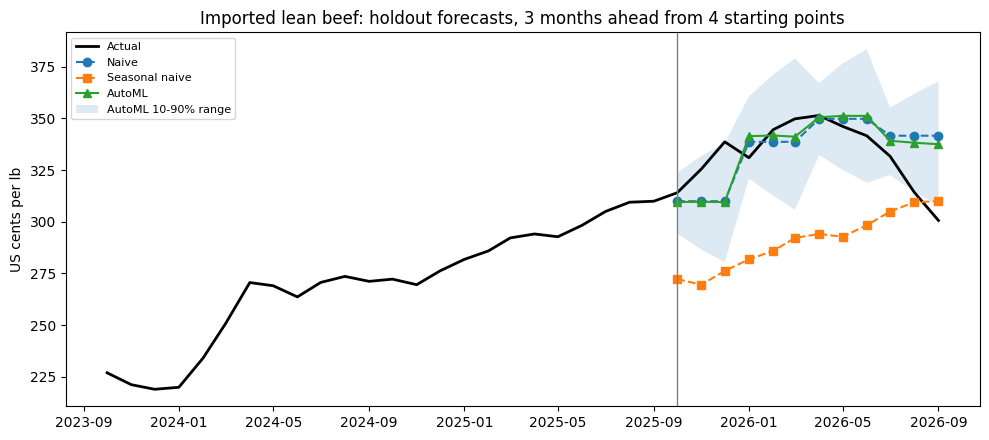

In [11]:
import matplotlib.pyplot as plt

recent = y[y.index >= holdout_months[0] - pd.DateOffset(months=24)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(recent.index, recent.values, color="black", lw=2, label="Actual")
ax.plot(fc["month"], fc["naive"], "o--", label="Naive")
ax.plot(fc["month"], fc["seasonal_naive"], "s--", label="Seasonal naive")
ax.plot(fc["month"], fc["automl"], "^-", label="AutoML")
ax.fill_between(fc["month"], fc["automl_p10"], fc["automl_p90"], alpha=0.15, label="AutoML 10-90% range")
ax.axvline(holdout_months[0], color="grey", lw=1)
ax.set_ylabel("US cents per lb")
ax.set_title("Imported lean beef: holdout forecasts, 3 months ahead from 4 starting points")
ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.savefig("holdout_chart.png", dpi=150)
plt.show()

## Step 9b. The next 3 months

The holdout test is finished, so now we can use **all** the data as the starting point and ask for the 3 months after the latest month. Two forecasts sit side by side: naive (the latest price, held flat) and AutoML with its 10% to 90% range.

One honest limit: the AutoML models were trained only on the data before the holdout. The statistical models refit on the latest data when they predict, but a production forecast would retrain everything on the full series first. Say this if you show these numbers.

The holdout result tells you how much to trust them. If AutoML did not beat naive on the holdout, lead with the **range**, not the central number.

In [12]:
future = predictor.predict(to_tsdf(y)).loc["beef"]
outlook = pd.DataFrame({
    "month": future.index,
    "naive": y.iloc[-1],
    "automl": future["mean"].to_numpy(),
    "automl_p10": future["0.1"].to_numpy(),
    "automl_p90": future["0.9"].to_numpy(),
}).round(2)
assert outlook["month"].iloc[0] == y.index[-1] + pd.DateOffset(months=1), "The outlook should start the month after the data ends"
print(f"Latest actual: {y.index[-1]:%b %Y} = {y.iloc[-1]:.2f} US cents/lb")
print(outlook.to_string(index=False))

Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble


Latest actual: Sep 2026 = 300.61 US cents/lb
     month  naive  automl  automl_p10  automl_p90
2026-10-01 300.61  296.89      280.93      312.27
2026-11-01 300.61  295.89      272.96      318.61
2026-12-01 300.61  295.21      266.64      323.86


## Step 10. Log the run

Every run adds rows to `experiment_log.csv`. One row per method, with the data fingerprints, the dates, the settings and the versions. A teammate could rerun exactly this experiment from the log.

In [13]:
import autogluon.timeseries as agts

run_info = {
    "run_id": RUN_ID,
    "run_time": datetime.now().isoformat(timespec="seconds"),
    "beef_file": f"{BEEF_FILE} md5={beef_md5}",
    "fx_file": f"{FX_FILE} md5={fx_md5}",
    "retail_file": f"{RETAIL_FILE} md5={retail_md5}",
    "train_period": f"{train.index.min():%Y-%m} to {train.index.max():%Y-%m}",
    "holdout_period": f"{holdout_months[0]:%Y-%m} to {holdout_months[-1]:%Y-%m}",
    "horizon_months": HORIZON,
    "forecast_starts": " ".join(f"{o:%Y-%m}" for o in origins),
    "automl": f"AutoGluon {agts.__version__}, presets=medium_quality, time_limit={TIME_LIMIT}, "
              f"num_val_windows=4, seed={SEED}, excluded={EXCLUDED_MODELS}",
    "automl_best_model": predictor.model_best,
    "automl_coverage_pct": round(coverage, 1),
    "warnings": n_warnings,
    "pandas": pd.__version__,
}

log = results.assign(**run_info)
log_path = "experiment_log.csv"
log.to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
with open(f"run_config_{RUN_ID}.json", "w") as f:
    json.dump(run_info, f, indent=2)
print(f"Added {len(log)} rows to {log_path}")

Added 4 rows to experiment_log.csv


## Step 11. Export for Excel

One workbook with six sheets. Excel builds the dashboard from these.

| Sheet | Contents |
|---|---|
| Data | The clean monthly table from Step 4 |
| Forecast | The 12 holdout months with every forecast |
| Metrics | The comparison table from Step 9, for cross-checking your Excel numbers |
| Checks | The data checks from Step 3 |
| Leaderboard | AutoGluon's own model scores from training |
| Outlook | The next 3 months from Step 9b |

In [14]:
data_out = clean.reset_index()
forecast_out = fc.round(3)
checks_out = checks.reset_index()
lb_out = leaderboard.reset_index(drop=True)

with pd.ExcelWriter("beef_dashboard_data.xlsx", engine="openpyxl",
                    date_format="yyyy-mm-dd", datetime_format="yyyy-mm-dd") as xw:
    data_out.to_excel(xw, sheet_name="Data", index=False)
    forecast_out.to_excel(xw, sheet_name="Forecast", index=False)
    results.to_excel(xw, sheet_name="Metrics", index=False)
    checks_out.to_excel(xw, sheet_name="Checks", index=False)
    lb_out.to_excel(xw, sheet_name="Leaderboard", index=False)
    outlook.to_excel(xw, sheet_name="Outlook", index=False)

# Make the workbook easy to read: dates as "Oct 2025", sensible column widths, header row frozen
from openpyxl import load_workbook
wb = load_workbook("beef_dashboard_data.xlsx")
for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    for col in ws.columns:
        header = str(col[0].value)
        ws.column_dimensions[col[0].column_letter].width = 60 if header == "note" else max(len(header), 10) + 3
        if header in ("month", "forecast_start"):
            for cell in col[1:]:
                cell.number_format = "mmm yyyy"
wb.save("beef_dashboard_data.xlsx")

clean.to_csv("beef_monthly_clean.csv")
print("Saved beef_dashboard_data.xlsx, beef_monthly_clean.csv, experiment_log.csv and holdout_chart.png")

try:                                   # downloads the files when running in Colab
    from google.colab import files
    for name in ["beef_dashboard_data.xlsx", "beef_monthly_clean.csv",
                 "experiment_log.csv", "holdout_chart.png"]:
        files.download(name)
except ImportError:
    pass

Saved beef_dashboard_data.xlsx, beef_monthly_clean.csv, experiment_log.csv and holdout_chart.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>